### Imports e etc...
bibliotecas para a limpeza de dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from IPython.display import display, HTML, Markdown
from pathlib import Path
import sys

ROOT: Path = Path.cwd().parent
while str(ROOT) in sys.path:
    sys.path.remove(str(ROOT))
sys.path.insert(0, str(ROOT))

from src.logger_mk import table_with_limit, printf

In [2]:
external = pd.read_excel(
    "data/gmindex_research.xlsx",
    sheet_name='External'
)

df = external.copy() # why not use external directly?

In [3]:
df

,2024 UN EGDI,Unnamed: 1,Unnamed: 2,Unnamed: 3,I-27,I-18,I-44,I-16,Unnamed: 8,2024 ITU GCI,Unnamed: 10,Unnamed: 11,I-43,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17
0,Code,Country Name,E-Gov Rank,E-Gov Index,E-Particip Index,Online Service Index,Human Capital Index,Telecom Infra Index,NaN,Code,Economy,GCI Tier,GCI,Legal Measures,Technical,Organizational,Capacity Development,Cooperation
1,AFG,Afghanistan,188,0.20827,0.1096,0.14379,0.2643,0.21672,NaN,AFG,Afghanistan,T5,18.41,5.81,3.29,6.99,2.32,0
2,ALB,Albania,62,0.8,0.726,0.81441,0.81059,0.77497,NaN,ALB,Albania,T2,86.51,20,18.38,19.47,12.08,16.58
3,DZA,Algeria,116,0.59556,0.0548,0.332,0.64179,0.8129,NaN,DZA,Algeria,T3,65.87,19.18,8.57,11.02,13.91,13.19
4,AND,Andorra,88,0.68931,0.5479,0.47804,0.66684,0.92307,NaN,AND,Andorra,T3,76.66,18.04,15.3,13.88,11.74,17.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191,YEM,Yemen,185,0.23175,0.1507,0.13774,0.26704,0.29045,NaN,YEM,Yemen,T5,7.19,5.29,1.9,0,0,0
192,ZMB,Zambia,130,0.54237,0.411,0.49584,0.62252,0.5088,NaN,ZMB,Zambia,T2,92.59,20,17.62,20,14.97,20
193,ZWE,Zimbabwe,149,0.44807,0.274,0.41003,0.5395,0.39471,NaN,ZWE,Zimbabwe,T4,39.85,16.3,1.39,7.38,6.81,7.97
194,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
printf("Anomalia no Dataset")
display(df.iloc[194:196, 0:18]) # remover

printf("Os dados do Vaticano, que está disponivel no 2024 ITU GCI, mas não 2024 UN EGDI. Então não será considerado")
display(df.iloc[195:196, 9:18]) 
# Com 193 países um não é tão relevante assim, pois o Vaticano não é um país, mas sim uma cidade-estado. Então não será considerado.
# é complexo, mas ele por si só é um outlier, por causa da sua específicidade.

df = df.drop(index=[194, 195]) # remover o vaticano e a anomalia do dataset

Anomalia no Dataset

,2024 UN EGDI,Unnamed: 1,Unnamed: 2,Unnamed: 3,I-27,I-18,I-44,I-16,Unnamed: 8,2024 ITU GCI,Unnamed: 10,Unnamed: 11,I-43,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17
194,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
195,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,VAT,Vatican,T5,9.07,1.41,0,3.62,2.91,1.13


Os dados do Vaticano, que está disponivel no 2024 ITU GCI, mas não 2024 UN EGDI. Então não será considerado

,2024 ITU GCI,Unnamed: 10,Unnamed: 11,I-43,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17
195,VAT,Vatican,T5,9.07,1.41,0,3.62,2.91,1.13


In [5]:
display(df.iloc[:,0:8])
display(df.iloc[:,8:18])

,2024 UN EGDI,Unnamed: 1,Unnamed: 2,Unnamed: 3,I-27,I-18,I-44,I-16
0,Code,Country Name,E-Gov Rank,E-Gov Index,E-Particip Index,Online Service Index,Human Capital Index,Telecom Infra Index
1,AFG,Afghanistan,188,0.20827,0.1096,0.14379,0.2643,0.21672
2,ALB,Albania,62,0.8,0.726,0.81441,0.81059,0.77497
3,DZA,Algeria,116,0.59556,0.0548,0.332,0.64179,0.8129
4,AND,Andorra,88,0.68931,0.5479,0.47804,0.66684,0.92307
...,...,...,...,...,...,...,...,...
189,VEN,Venezuela,131,0.53603,0.2192,0.35756,0.71149,0.53905
190,VNM,Viet Nam,71,0.77092,0.6027,0.70811,0.72665,0.87797
191,YEM,Yemen,185,0.23175,0.1507,0.13774,0.26704,0.29045
192,ZMB,Zambia,130,0.54237,0.411,0.49584,0.62252,0.5088


,Unnamed: 8,2024 ITU GCI,Unnamed: 10,Unnamed: 11,I-43,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17
0,NaN,Code,Economy,GCI Tier,GCI,Legal Measures,Technical,Organizational,Capacity Development,Cooperation
1,NaN,AFG,Afghanistan,T5,18.41,5.81,3.29,6.99,2.32,0
2,NaN,ALB,Albania,T2,86.51,20,18.38,19.47,12.08,16.58
3,NaN,DZA,Algeria,T3,65.87,19.18,8.57,11.02,13.91,13.19
4,NaN,AND,Andorra,T3,76.66,18.04,15.3,13.88,11.74,17.7
...,...,...,...,...,...,...,...,...,...,...
189,NaN,VEN,Venezuela,T4,30.42,15.01,4.56,2.23,4.69,3.93
190,NaN,VNM,Viet Nam,T1,99.74,20,20,20,19.74,20
191,NaN,YEM,Yemen,T5,7.19,5.29,1.9,0,0,0
192,NaN,ZMB,Zambia,T2,92.59,20,17.62,20,14.97,20


In [6]:
if "Unnamed: 8" in df.columns and (num_nulls := df['Unnamed: 8'].isnull().sum()) == len(df):
    printf("A coluna 'Unnamed: 8' está completamente vazia, então será removida")
    printf(f"Valores nulos na coluna 'Unnamed: 8': {num_nulls}")
    df = df.drop(columns=['Unnamed: 8'])
    del num_nulls
else:
    printf("A coluna 'Unnamed: 8' não existe no DataFrame")

printf("Comparando as colunas '2024 UN EGDI' e '2024 ITU GCI' para verificar se são iguais")
if '2024 UN EGDI' in df.columns and '2024 ITU GCI' in df.columns:
    # Não são iguais, verificando as linhas diferentes, acredito que seja uma questão de embaralhamento
    # dividindo o dataset em duas partes e depois fazer um inner join
    printf(f"Resultado: {df['2024 UN EGDI'].equals(df['2024 ITU GCI'])}")
    df.loc[df["2024 UN EGDI"] != df["2024 ITU GCI"]]

    printf("Dividindo o dataset em duas partes e depois fazer um inner join")
    df_part1 = df.iloc[:,0:8].copy() # atributo chave 2024 UN EGDI
    df_part2 = df.iloc[:,8:18].copy() # atributo chave 2024 ITU GCI

    df_merged = pd.merge(
        df_part1, 
        df_part2, 
        left_on="2024 UN EGDI", 
        right_on="2024 ITU GCI", 
        how="inner"
    )
    df = df_merged.copy()
    del df_part1, df_part2, df_merged # free memory

    printf("Ajustando o DataFrame para ter a primeira linha como cabeçalho")
    df.columns = df.iloc[0]
    df = df.iloc[1:].reset_index(drop=True)
else:
    printf("Uma ou ambas as colunas '2024 UN EGDI' e '2024 ITU GCI' não existem no DataFrame")

printf("Comparando se as colunas 'Country Name' e 'Economy' são iguais")

if 'Country Name' in df.columns and 'Economy' in df.columns:
    printf(f"Resultado: {df['Country Name'].equals(df['Economy'])}")
    sus_countries = df.loc[df["Country Name"] != df["Economy"], ["Country Name", "Economy"]]
    # Essa avalicão pode ser feita manualmente...
    printf(f"Países diferentes entre as duas colunas são no total de {len(sus_countries)} países")
    display(sus_countries)

    printf("Usando o bom senso, vamos manter a coluna 'Country Name' e remover a coluna 'Economy', pois ela é redundante")
    df = df.drop(columns=['Economy']) 
else:
    printf("Uma ou ambas as colunas 'Country Name' e 'Economy' não existem no DataFrame")
    
# dropar também a coluna 'Code', pois ela é redundante, pois o código do país é o mesmo para as duas colunas
df = df.loc[:, ~df.columns.duplicated()]

display(Markdown("Resultado do merge entre as duas partes do dataset, algo mais harmónico, mas ainda assim não é perfeito, pois o dataset original tinha 193 países e agora tem 192 países, então algum país foi perdido no merge"))
display(Markdown("faz parte da vida... enfim"))
display(df)



A coluna 'Unnamed: 8' está completamente vazia, então será removida

Valores nulos na coluna 'Unnamed: 8': 194

Comparando as colunas '2024 UN EGDI' e '2024 ITU GCI' para verificar se são iguais

Resultado: False

Dividindo o dataset em duas partes e depois fazer um inner join

Ajustando o DataFrame para ter a primeira linha como cabeçalho

... (4 outputs left out)

Usando o bom senso, vamos manter a coluna 'Country Name' e remover a coluna 'Economy', pois ela é redundante

Resultado do merge entre as duas partes do dataset, algo mais harmónico, mas ainda assim não é perfeito, pois o dataset original tinha 193 países e agora tem 192 países, então algum país foi perdido no merge

faz parte da vida... enfim

,Code,Country Name,E-Gov Rank,E-Gov Index,E-Particip Index,Online Service Index,Human Capital Index,Telecom Infra Index,GCI Tier,GCI,Legal Measures,Technical,Organizational,Capacity Development,Cooperation
0,AFG,Afghanistan,188,0.20827,0.1096,0.14379,0.2643,0.21672,T5,18.41,5.81,3.29,6.99,2.32,0
1,ALB,Albania,62,0.8,0.726,0.81441,0.81059,0.77497,T2,86.51,20,18.38,19.47,12.08,16.58
2,DZA,Algeria,116,0.59556,0.0548,0.332,0.64179,0.8129,T3,65.87,19.18,8.57,11.02,13.91,13.19
3,AND,Andorra,88,0.68931,0.5479,0.47804,0.66684,0.92307,T3,76.66,18.04,15.3,13.88,11.74,17.7
4,AGO,Angola,156,0.41487,0.2192,0.39624,0.47602,0.37238,T4,39.49,13.67,1.78,5.8,2.91,15.33
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187,VEN,Venezuela,131,0.53603,0.2192,0.35756,0.71149,0.53905,T4,30.42,15.01,4.56,2.23,4.69,3.93
188,VNM,Viet Nam,71,0.77092,0.6027,0.70811,0.72665,0.87797,T1,99.74,20,20,20,19.74,20
189,YEM,Yemen,185,0.23175,0.1507,0.13774,0.26704,0.29045,T5,7.19,5.29,1.9,0,0,0
190,ZMB,Zambia,130,0.54237,0.411,0.49584,0.62252,0.5088,T2,92.59,20,17.62,20,14.97,20


Para essa pesquisa, eu selecionei os países por representatividade estratégica. Para isso, como o alvo é:
- Governo digital (E-Government): maturidade dos serviços públicos digitais, participação eletrônica, capital humano e infraestrutura de telecomunicações.
- Cibersegurança nacional (Global Cybersecurity Index): maturidade jurídica, técnica, organizacional, desenvolvimento de capacidades e cooperação internacional.

Se faz necessário identificar países que apresentam maturidade elevada em governo digital e cibersegurança, além daqueles em que existe uma diferença significativa entre essas dimensões.

---

| País | Papel na comparação | Justificativa |
|---|---|---|
| Brasil | Referência principal | País de interesse e referência para comparação. |
| Uruguai | Referência regional | Permite comparar o Brasil com outro país sul-americano de maturidade digital relevante. |
| Venezuela | Referência regional | Interessante para observar diferenças de desenvolvimento digital na América Latina. |
| Estônia | Referência em governo digital | Reconhecida pela digitalização dos serviços públicos e pela infraestrutura digital. |
| Dinamarca | Referência global | Um dos principais exemplos de maturidade em governo eletrônico. |
| Estados Unidos | Referência global | Um dos principais agentes influenciadores do mundo |
| Singapura | Referência tecnológica | Forte integração entre governo digital, infraestrutura e cibersegurança. |
| Coreia do Sul | Referência tecnológica | Destaque em serviços digitais e infraestrutura de telecomunicações. |
| Índia | Referência de escala | Permite observar a transformação digital e a cibersegurança em um país populoso e emergente. |

In [14]:
brazil_data = df[df["Country Name"] == "Brazil"]
uruguay_data = df[df["Country Name"] == "Uruguay"]
venezuela_data = df[df["Country Name"] == "Venezuela"]
estados_unidos_data = df[df["Country Name"] == "United States"]
estonia_data = df[df["Country Name"] == "Estonia"]
singapore_data = df[df["Country Name"] == "Singapore"]
south_korea_data = df[df["Country Name"] == "South Korea"]
india_data = df[df["Country Name"] == "India"]

focus_df = pd.concat([
    brazil_data,
    uruguay_data,
    venezuela_data,
    estados_unidos_data,
    estonia_data,
    singapore_data,
    south_korea_data,
    india_data
])
focus_df = focus_df.reset_index(drop=True)
focus_df

,Code,Country Name,E-Gov Rank,E-Gov Index,E-Particip Index,Online Service Index,Human Capital Index,Telecom Infra Index,GCI Tier,GCI,Legal Measures,Technical,Organizational,Capacity Development,Cooperation
0,BRA,Brazil,50,0.84026,0.863,0.90631,0.80768,0.80685,T1,96.38,20,20,17.29,19.09,20
1,URY,Uruguay,25,0.90059,0.863,0.88321,0.87488,0.94374,T2,94.69,19.15,20,19.51,19.45,16.58
2,VEN,Venezuela,131,0.53603,0.2192,0.35756,0.71149,0.53905,T4,30.42,15.01,4.56,2.23,4.69,3.93
3,EST,Estonia,2,0.97274,0.9589,0.99535,0.94972,0.97309,T1,95.04,20,15.3,20,19.74,20
4,SGP,Singapore,3,0.96912,0.9589,0.98306,0.93615,0.98806,T1,99.86,20,20,20,19.86,20
5,IND,India,97,0.66776,0.6575,0.81842,0.61487,0.57004,T1,98.49,20,20,18.49,20,20


In [23]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Variáveis desagregadas
features = [
    "E-Particip Index",
    "Online Service Index",
    "Human Capital Index",
    "Telecom Infra Index",
    "Legal Measures",
    "Technical",
    "Organizational",
    "Capacity Development",
    "Cooperation"
]

# Preparação
X = df[features].copy()
X[features] = X[features].apply(pd.to_numeric, errors="coerce")

display(X.head())
display(X.dtypes)
assert X.select_dtypes(include=np.number).shape[1] == len(features)

X = X.replace([np.inf, -np.inf], np.nan)

# Tratar valores ausentes
X = X.fillna(X.median())

# Normalização
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Avaliação de diferentes K
results = []

for k in range(2, 20):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(
            X_scaled, labels
        ),
        "calinski_harabasz": calinski_harabasz_score(
            X_scaled, labels
        )
    })

metrics = pd.DataFrame(results)

print(metrics)

,E-Particip Index,Online Service Index,Human Capital Index,Telecom Infra Index,Legal Measures,Technical,Organizational,Capacity Development,Cooperation
0,0.1096,0.14379,0.26430,0.21672,5.81,3.29,6.99,2.32,0.00
1,0.7260,0.81441,0.81059,0.77497,20.00,18.38,19.47,12.08,16.58
2,0.0548,0.33200,0.64179,0.81290,19.18,8.57,11.02,13.91,13.19
3,0.5479,0.47804,0.66684,0.92307,18.04,15.30,13.88,11.74,17.70
4,0.2192,0.39624,0.47602,0.37238,13.67,1.78,5.80,2.91,15.33


0
E-Particip Index        float64
Online Service Index    float64
Human Capital Index     float64
Telecom Infra Index     float64
Legal Measures          float64
Technical               float64
Organizational          float64
Capacity Development    float64
Cooperation             float64
dtype: object

     k     inertia  silhouette  davies_bouldin  calinski_harabasz
0    2  739.185927    0.473483        0.817165         254.164300
1    3  566.180834    0.363196        1.172617         193.916686
2    4  489.369926    0.335118        1.281038         158.613789
3    5  418.400024    0.325997        1.321807         146.328383
4    6  374.036351    0.321157        1.194373         134.659232
5    7  345.475329    0.253173        1.277566         123.388967
6    8  322.218595    0.256606        1.268465         114.679813
7    9  306.350678    0.251837        1.323772         106.153603
8   10  290.938045    0.238040        1.376322          99.885824
9   11  276.336160    0.223131        1.423937          95.083884
10  12  265.737910    0.235791        1.386959          90.043326
11  13  255.268919    0.226296        1.340148          86.059199
12  14  242.960279    0.218957        1.445046          83.691132
13  15  236.884541    0.211731        1.434216          79.582904
14  16  22

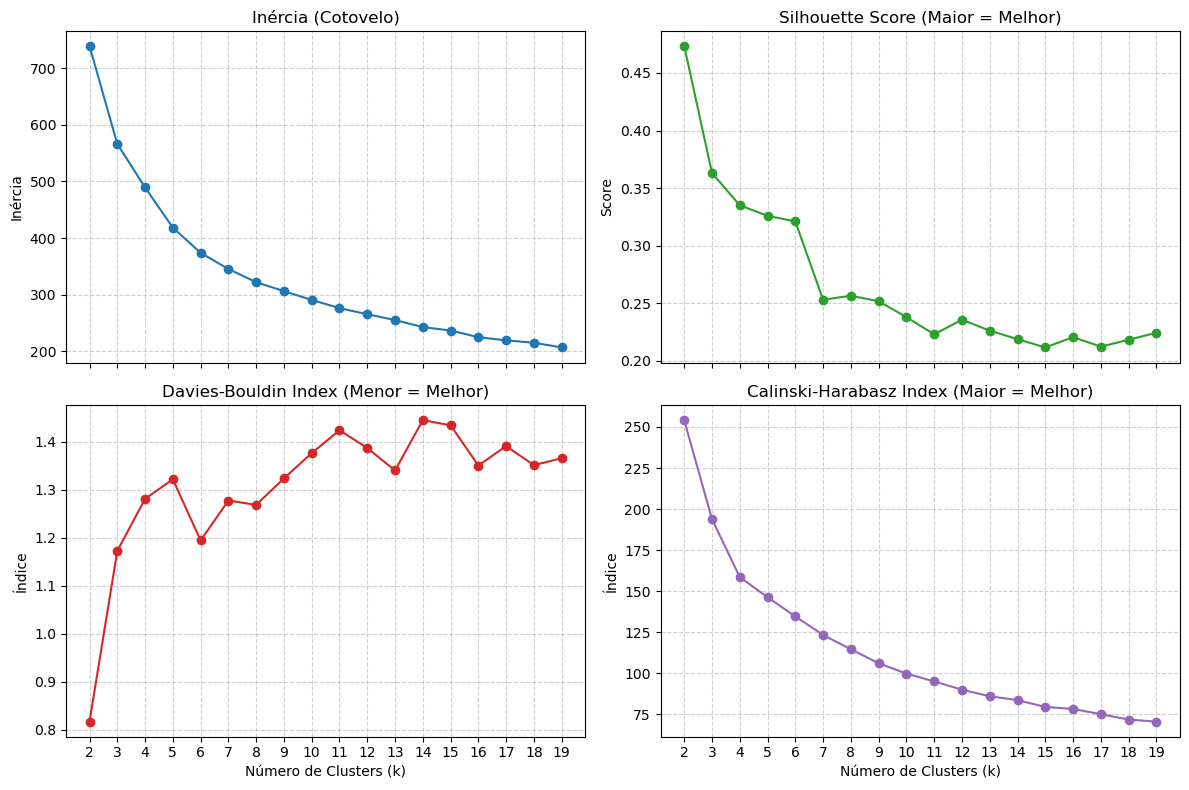

In [24]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)

# Inércia (Método do Cotovelo)
axes[0, 0].plot(metrics["k"], metrics["inertia"], marker="o", color="tab:blue")
axes[0, 0].set_title("Inércia (Cotovelo)")
axes[0, 0].set_ylabel("Inércia")
axes[0, 0].grid(True, linestyle="--", alpha=0.6)

# Silhouette Score (Quanto maior, melhor)
axes[0, 1].plot(metrics["k"], metrics["silhouette"], marker="o", color="tab:green")
axes[0, 1].set_title("Silhouette Score (Maior = Melhor)")
axes[0, 1].set_ylabel("Score")
axes[0, 1].grid(True, linestyle="--", alpha=0.6)

# Davies-Bouldin Index (Quanto menor, melhor)
axes[1, 0].plot(metrics["k"], metrics["davies_bouldin"], marker="o", color="tab:red")
axes[1, 0].set_title("Davies-Bouldin Index (Menor = Melhor)")
axes[1, 0].set_xlabel("Número de Clusters (k)")
axes[1, 0].set_ylabel("Índice")
axes[1, 0].grid(True, linestyle="--", alpha=0.6)

# Calinski-Harabasz Index (Quanto maior, melhor)
axes[1, 1].plot(metrics["k"], metrics["calinski_harabasz"], marker="o", color="tab:purple")
axes[1, 1].set_title("Calinski-Harabasz Index (Maior = Melhor)")
axes[1, 1].set_xlabel("Número de Clusters (k)")
axes[1, 1].set_ylabel("Índice")
axes[1, 1].grid(True, linestyle="--", alpha=0.6)

# Garante que todos os valores inteiros de k apareçam no eixo X
plt.xticks(metrics["k"])
plt.tight_layout()
plt.show()

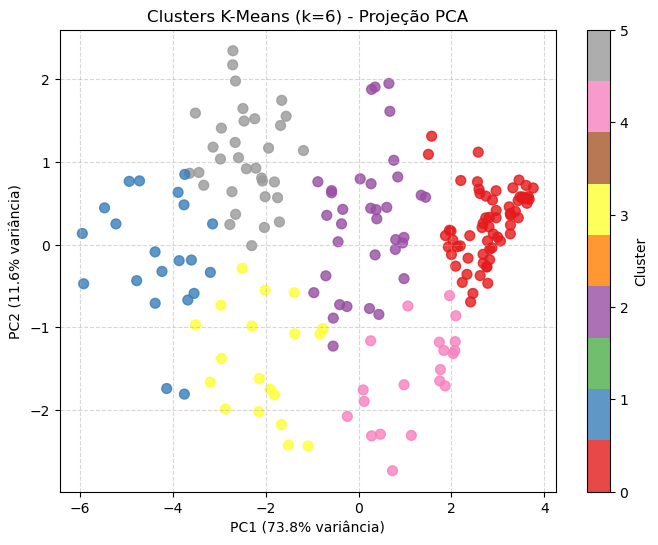

In [33]:
from sklearn.decomposition import PCA

k_escolhido = 6
kmeans_final = KMeans(n_clusters=k_escolhido, random_state=42, n_init=20)
clusters = kmeans_final.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap="Set1", s=50, alpha=0.8)
plt.title(f"Clusters K-Means (k={k_escolhido}) - Projeção PCA")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variância)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variância)")
plt.colorbar(scatter, label="Cluster") 
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

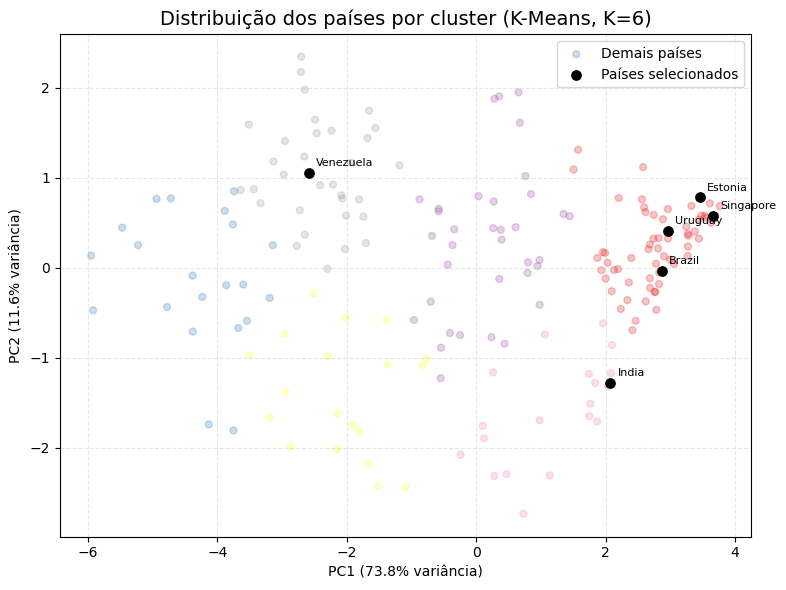

In [42]:
import matplotlib.pyplot as plt
import pandas as pd

# Índices dos países selecionados
focus_indices = df[
    df["Country Name"].isin([
        "Brazil",
        "Uruguay",
        "Venezuela",
        "United States",
        "Estonia",
        "Singapore",
        "South Korea",
        "India"
    ])
].index

# Coordenadas PCA dos países selecionados
focus_pca = X_pca[focus_indices]

# Identificação dos países
focus_names = df.loc[focus_indices, "Country Name"]

plt.figure(figsize=(8, 6))

# Todos os países em segundo plano
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="Set1",
    s=25,
    alpha=0.25,
    label="Demais países"
)

# Países selecionados em destaque
plt.scatter(
    focus_pca[:, 0],
    focus_pca[:, 1],
    color="black",
    # edgecolors="white",
    # linewidths=1.5,
    s=45,
    zorder=5,
    label="Países selecionados"
)

# Rótulos
for i, name in enumerate(focus_names):
    plt.annotate(
        name,
        (focus_pca[i, 0], focus_pca[i, 1]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
        # fontweight="bold"
    )

plt.title(
    f"Distribuição dos países por cluster (K-Means, K={k_escolhido})",
    fontsize=14
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variância)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variância)"
)

plt.legend()
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

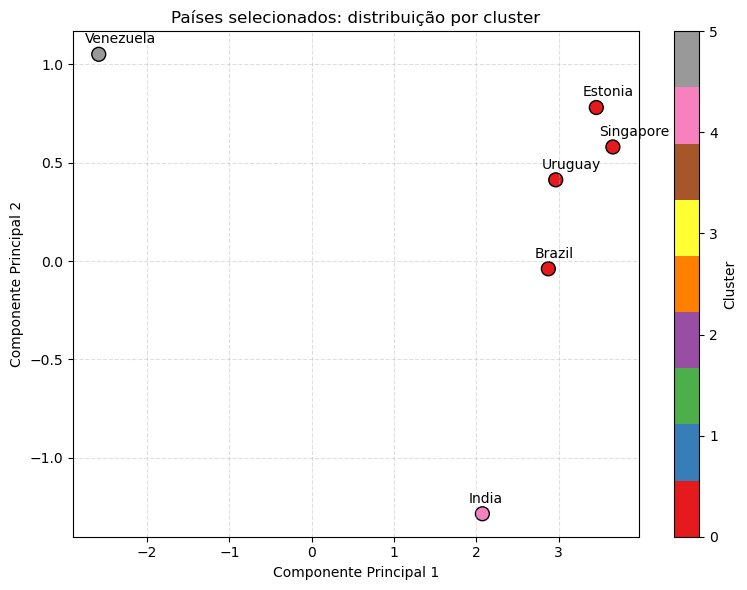

In [57]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    focus_pca[:, 0],
    focus_pca[:, 1],
    c=clusters[focus_indices],
    cmap="Set1",
    s=100,
    edgecolors="black",
    linewidths=1
)

for i, name in enumerate(focus_names):
    plt.annotate(
        name,
        (focus_pca[i, 0], focus_pca[i, 1]),
        xytext=(-10, 8),
        textcoords="offset points",
        fontsize=10,
        # fontweight="bold"
    )

plt.title("Países selecionados: distribuição por cluster")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")

plt.colorbar(scatter, label="Cluster")

plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()